In [46]:
import pandas as pd
import seaborn as sns
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [62]:
cereal = pd.read_csv('cereal.csv', index_col=0)
cereal.head()

,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
name,,,,,,,,,,,,,,,
100% Bran,N,C,70,4,1,130,10.0,5.0,6,280,25,3,1.0,0.33,68.402973
100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8,135,0,3,1.0,1.00,33.983679
All-Bran,K,C,70,4,1,260,9.0,7.0,5,320,25,3,1.0,0.33,59.425505
All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0,330,25,3,1.0,0.50,93.704912
Almond Delight,R,C,110,2,2,200,1.0,14.0,8,-1,25,3,1.0,0.75,34.384843


In [63]:
cereal.shape

(77, 15)

In [64]:
cereal = cereal.drop_duplicates()
cereal = cereal.dropna()
cereal.shape

(77, 15)

In [65]:
cereal.describe().T

,count,mean,std,min,25%,50%,75%,max
calories,77.0,106.883117,19.484119,50.000000,100.000000,110.000000,110.000000,160.000000
protein,77.0,2.545455,1.094790,1.000000,2.000000,3.000000,3.000000,6.000000
fat,77.0,1.012987,1.006473,0.000000,0.000000,1.000000,2.000000,5.000000
sodium,77.0,159.675325,83.832295,0.000000,130.000000,180.000000,210.000000,320.000000
fiber,77.0,2.151948,2.383364,0.000000,1.000000,2.000000,3.000000,14.000000
carbo,77.0,14.597403,4.278956,-1.000000,12.000000,14.000000,17.000000,23.000000
sugars,77.0,6.922078,4.444885,-1.000000,3.000000,7.000000,11.000000,15.000000
potass,77.0,96.077922,71.286813,-1.000000,40.000000,90.000000,120.000000,330.000000
vitamins,77.0,28.246753,22.342523,0.000000,25.000000,25.000000,25.000000,100.000000
shelf,77.0,2.207792,0.832524,1.000000,1.000000,2.000000,3.000000,3.000000


In [66]:
print(cereal['mfr'].unique())
print(cereal['type'].unique())

['N' 'Q' 'K' 'R' 'G' 'P' 'A']
['C' 'H']


In [67]:
cereal = pd.get_dummies(cereal, columns=["mfr", "type"], drop_first=True, dtype="float32")

In [68]:
X = cereal.drop(columns=["rating", "name"], errors="ignore")
y = cereal["rating"].values.astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [69]:
input_shape = (X_train.shape[1],) 
print(input_shape)

(19,)


In [70]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])

In [71]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mae",
    metrics=["mse"],
)

In [73]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    min_delta=0.01,
    restore_best_weights=True,
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=16,
    epochs=300,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - loss: 42.9611 - mse: 2033.8105 - val_loss: 37.2449 - val_mse: 1590.5134
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 39.7157 - mse: 1739.2001 - val_loss: 33.5207 - val_mse: 1312.7052
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 34.9882 - mse: 1384.8176 - val_loss: 27.4325 - val_mse: 932.3169
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 26.9664 - mse: 888.5001 - val_loss: 18.3908 - val_mse: 508.2390
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 15.7504 - mse: 421.5570 - val_loss: 11.8320 - val_mse: 226.6704
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 10.9081 - mse: 181.3705 - val_loss: 12.6896 - val_mse: 230.6092
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 14.1094 - mse: 312.0186 - val_loss: 9.7837 - val_mse: 185.6324
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 9.3136 - mse: 137.9154 - val_loss: 7.6133 - val_mse: 109.8137
Epoch 9/300
4/4 ━━━━━━

Validation MAE: 3.302 | Validation RMSE: 4.226 | Test R²: 0.919

--- Sample Predictions ---
Actual: 34.38 | Predicted: 36.99 | Diff: 2.61
Actual: 21.87 | Predicted: 19.56 | Diff: 2.31
Actual: 18.04 | Predicted: 20.18 | Diff: 2.14
Actual: 68.40 | Predicted: 70.17 | Diff: 1.76
Actual: 34.14 | Predicted: 33.90 | Diff: 0.24


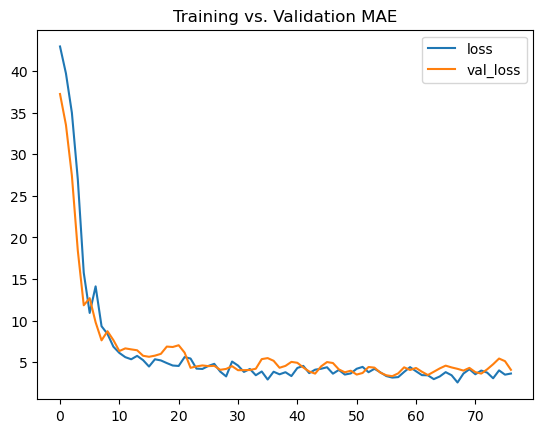

In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
history_df = pd.DataFrame(history.history)
preds = model.predict(X_test, verbose=0).flatten()
history_df[["loss", "val_loss"]].plot(title="Training vs. Validation MAE")
val_mae, val_mse = model.evaluate(X_test, y_test, verbose=0)
print(f"Validation MAE: {val_mae:.3f} | Validation RMSE: {np.sqrt(val_mse):.3f} | Test R²: {r2_score(y_test, preds):.3f}")


print("\n--- Sample Predictions ---")
for actual, pred in zip(y_valid[:5], preds[:5]):
    print(
        f"Actual: {actual:,.2f} | Predicted: {pred:,.2f} | Diff: {abs(actual - pred):,.2f}"
    )